# Multi-Strategy Algorithmic Trading Backtest on SPY
### Technical Indicators, a Causal Backtest Engine, and Strategy Comparison

## Problem Statement
Technical traders rely on indicators such as moving averages, oscillators, and volatility bands to decide when to hold an asset and when to stay in cash. This notebook asks a simple question: **do rule-based technical strategies improve on simply buying and holding the S&P 500 ETF (SPY)?**

To answer it, we download daily SPY prices, explore them, implement 12 well-known strategies with the `pandas_ta` indicator library, and evaluate each one with a vectorized backtest that avoids look-ahead bias and charges transaction costs.

## Roadmap
| Section | Topic | Main tools |
|---|---|---|
| 1 | Libraries and Data Loading | `yfinance`, `pandas` |
| 2 | Exploratory Data Analysis | `describe()`, `matplotlib`, `seaborn` |
| 3 | Technical Indicators and Strategy Definitions | `pandas_ta` |
| 4 | Backtest Engine and Performance Metrics | `pandas`, `numpy` |
| 5 | Multi-Strategy Comparison | `matplotlib`, `seaborn` |
| 6 | Single-Strategy Deep Dive and Conclusion | trade ledger, entry/exit markers |

## The 12 Strategies
Every strategy produces a daily **signal**: `1` means "be long SPY" and `0` means "stay in cash".

| # | Strategy | Category | Entry / Exit Rule |
|---|---|---|---|
| 1 | MACD Crossover (12, 26, 9) | Momentum | Buy when the MACD histogram turns positive; sell when it turns negative |
| 2 | RSI 30/70 (14) | Mean reversion | Buy when RSI(14) < 30; sell when RSI(14) > 70 |
| 3 | Donchian Breakout (20/10) | Trend following | Buy when Close exceeds the prior 20-day high; sell when Close falls below the prior 10-day low |
| 4 | Rate of Change (60) | Momentum | Hold while the 60-day return is positive |
| 5 | Z-Score Reversion (20) | Mean reversion | Buy when the 20-day z-score < -2; sell when it returns to 0 or above |
| 6 | Keltner Breakout (20, 2 ATR) | Volatility | Buy when Close > EMA(20) + 2 x ATR(20); sell when Close <= EMA(20) |
| 7 | SMA Crossover (50/200) | Trend following | Hold while SMA(50) > SMA(200) |
| 8 | Bollinger Reversion (20, 2) | Mean reversion | Buy when Close < lower band; sell when Close >= middle band |
| 9 | ATR Breakout (14) | Volatility | Buy when Close > previous Close + 1.5 x previous ATR; exit with a 2 x ATR trailing stop |
| 10 | Supertrend (10, 3) | Trend following | Hold while the Supertrend direction is up |
| 11 | Stochastic (14, 3) | Mean reversion | Buy on a bullish %K/%D cross below 20; sell on a bearish cross above 80 |
| 12 | SMA200 + RSI(2) Pullback | Hybrid | Buy when Close > SMA(200) and RSI(2) < 10; sell when Close > SMA(5) |

# 1. Libraries and Data Loading
We start by importing the libraries used throughout the notebook. Indicators come from `pandas_ta` (this environment provides it under the package name `pandas_ta_classic`, which has the same API), data come from `yfinance`, and every chart is drawn with `matplotlib` and `seaborn`.

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

try:
    import pandas_ta as ta
except ImportError:
    import pandas_ta_classic as ta   # same API, installed in this environment

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

## 1.1 Configuration and Download
All tunable settings are kept in one place. Transaction costs are expressed in **basis points** (1 bp = 0.01%) and are charged every time the position changes.

In [2]:
TICKER = "SPY"
START_DATE = "2020-01-01"
END_DATE = pd.Timestamp.today().strftime("%Y-%m-%d")

FEE_BPS = 1.0       # brokerage fee per trade, in basis points
SPREAD_BPS = 1.0    # bid-ask spread cost per trade, in basis points
TRADING_DAYS = 252  # trading days per year, used to annualize statistics


def load_data(ticker, start, end):
    """Download daily OHLCV data from Yahoo Finance.

    Args:
        ticker (str): The ticker symbol, for example "SPY".
        start (str): First date to download, formatted "YYYY-MM-DD".
        end (str): Last date to download, formatted "YYYY-MM-DD".

    Returns:
        pandas.DataFrame: Open, High, Low, Close, and Volume indexed by date.
    """
    data = yf.download(ticker, start=start, end=end, auto_adjust=True, progress=False)
    if isinstance(data.columns, pd.MultiIndex):
        data.columns = data.columns.get_level_values(0)   # drop the ticker level
    data = data[["Open", "High", "Low", "Close", "Volume"]]
    data.index = pd.to_datetime(data.index)
    return data


raw_df = load_data(TICKER, START_DATE, END_DATE)
raw_df.head()

Price,Open,High,Low,Close,Volume
Date,,,,,
2020-01-02,294.182509,295.410018,293.264146,295.391815,59151200
2020-01-03,292.018361,294.273339,291.963808,293.154938,77709700
2020-01-06,291.409181,294.355207,291.290972,294.273376,55653900
2020-01-07,293.709589,294.182422,293.000366,293.445923,40496400
2020-01-08,293.636833,296.219132,293.391343,295.009827,68296000


## 1.2 Inspecting and Cleaning the Data
We check the data types, look for missing values, and fill any gaps with the previous trading day's value (a forward fill), which never uses future information.

In [3]:
raw_df.info()
print("\nMissing values per column:")
print(raw_df.isna().sum())

<class 'pandas.DataFrame'>
DatetimeIndex: 1732 entries, 2020-01-02 to 2026-11-20
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Open    1732 non-null   float64
 1   High    1732 non-null   float64
 2   Low     1732 non-null   float64
 3   Close   1732 non-null   float64
 4   Volume  1732 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 81.2 KB

Missing values per column:
Price
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64


In [4]:
# Forward-fill small gaps, then drop any rows that are still incomplete (e.g., at the very start)
df = raw_df.ffill().dropna().copy()

print(f"Rows before cleaning: {len(raw_df)}")
print(f"Rows after cleaning:  {len(df)}")
print(f"Period: {df.index[0].date()} to {df.index[-1].date()}")
df.tail()

Rows before cleaning: 1732
Rows after cleaning:  1732
Period: 2020-01-02 to 2026-11-20


Price,Open,High,Low,Close,Volume
Date,,,,,
2026-11-16,749.659973,749.820007,738.070007,739.950012,69207300
2026-11-17,738.390015,739.760010,727.000000,732.440002,71636300
2026-11-18,733.369995,735.059998,726.799988,730.200012,51804800
2026-11-19,737.460022,739.900024,715.650024,715.869995,76702600
2026-11-20,713.559998,718.289978,686.750000,689.809998,151049800


# 2. Exploratory Data Analysis (EDA)
Before building strategies we want to understand how SPY behaves. We compute daily percentage returns and summarize their distribution.

In [5]:
df["Return"] = df["Close"].pct_change()
returns = df["Return"].dropna()

returns.describe()

count    1731.000000
mean        0.000570
std         0.012642
min        -0.109424
25%        -0.004631
50%         0.000899
75%         0.006635
max         0.105019
Name: Return, dtype: float64

In [6]:
# Skewness and kurtosis show how far the returns are from a normal distribution
print(f"Annualized mean return: {returns.mean() * TRADING_DAYS:.2%}")
print(f"Annualized volatility:  {returns.std() * np.sqrt(TRADING_DAYS):.2%}")
print(f"Skewness:               {returns.skew():.3f}")
print(f"Excess kurtosis:        {returns.kurt():.3f}")
print(f"Worst day:              {returns.min():.2%} on {returns.idxmin().date()}")
print(f"Best day:               {returns.max():.2%} on {returns.idxmax().date()}")

Annualized mean return: 14.37%
Annualized volatility:  20.07%
Skewness:               -0.279
Excess kurtosis:        13.176
Worst day:              -10.94% on 2020-03-16
Best day:               10.50% on 2025-04-09


## 2.1 Visual Exploration
The 2x2 grid below shows (a) the closing price with 50- and 200-day moving averages, (b) the distribution of daily returns, (c) 21-day rolling volatility, and (d) the spread of daily returns for each calendar year.

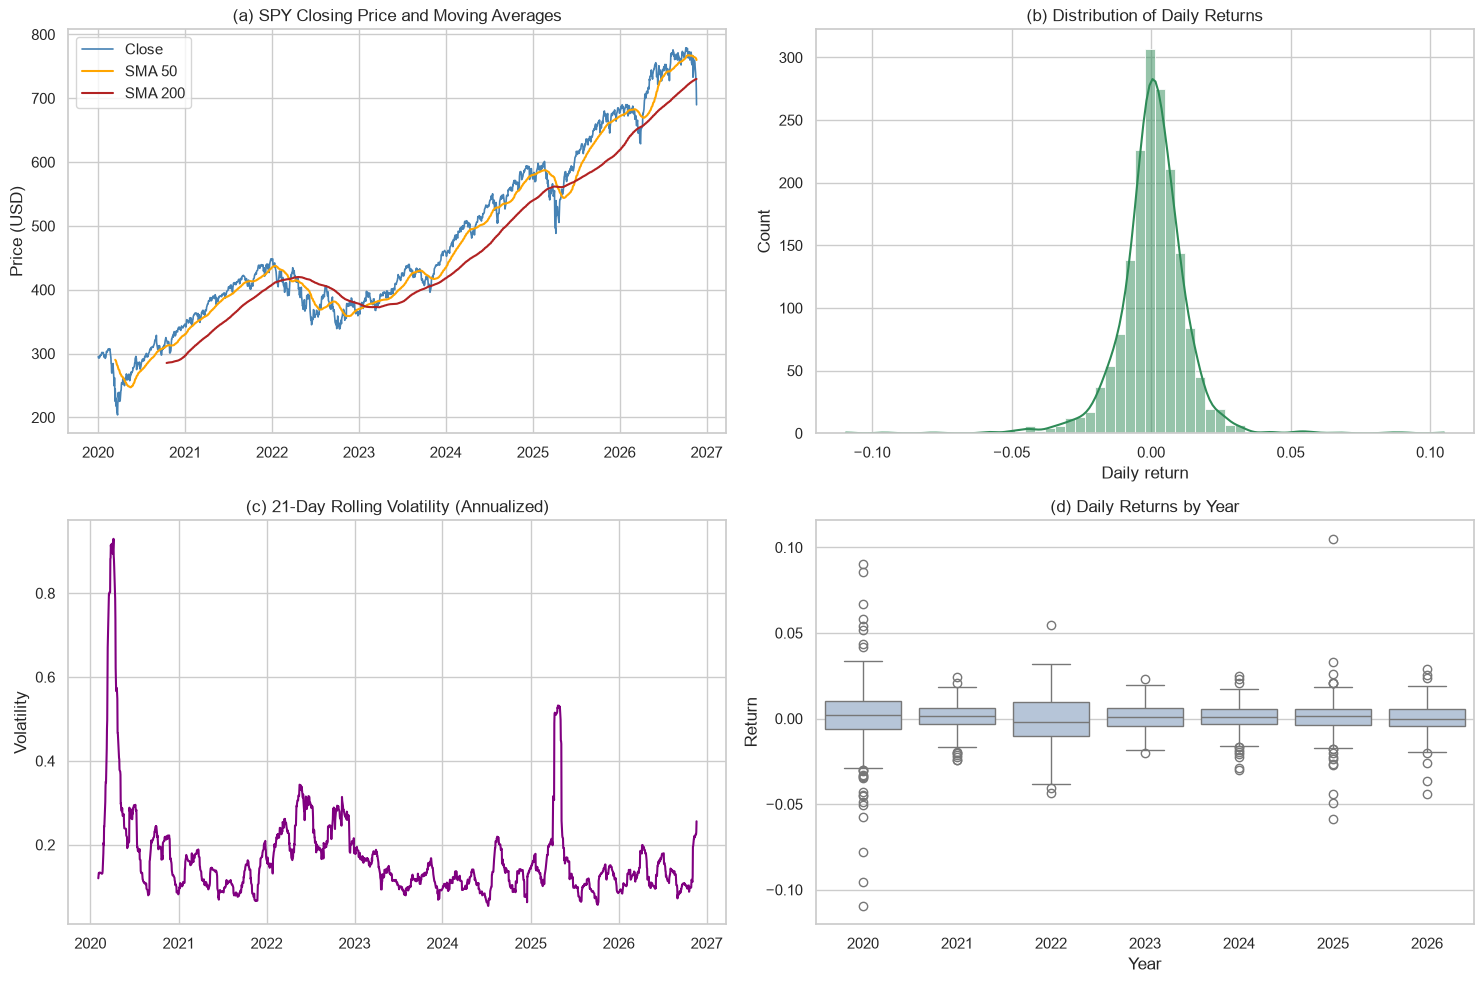

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# (a) Closing price and moving averages
axes[0, 0].plot(df.index, df["Close"], label="Close", color="steelblue", linewidth=1.2)
axes[0, 0].plot(df.index, df["Close"].rolling(50).mean(), label="SMA 50", color="orange")
axes[0, 0].plot(df.index, df["Close"].rolling(200).mean(), label="SMA 200", color="firebrick")
axes[0, 0].set_title("(a) SPY Closing Price and Moving Averages")
axes[0, 0].set_ylabel("Price (USD)")
axes[0, 0].legend()

# (b) Histogram of daily returns
sns.histplot(returns, bins=60, kde=True, color="seagreen", ax=axes[0, 1])
axes[0, 1].set_title("(b) Distribution of Daily Returns")
axes[0, 1].set_xlabel("Daily return")

# (c) Rolling volatility (annualized)
rolling_vol = returns.rolling(21).std() * np.sqrt(TRADING_DAYS)
axes[1, 0].plot(rolling_vol.index, rolling_vol, color="purple")
axes[1, 0].set_title("(c) 21-Day Rolling Volatility (Annualized)")
axes[1, 0].set_ylabel("Volatility")

# (d) Boxplot of returns by year
by_year = pd.DataFrame({"Return": returns, "Year": returns.index.year})
sns.boxplot(data=by_year, x="Year", y="Return", color="lightsteelblue", ax=axes[1, 1])
axes[1, 1].set_title("(d) Daily Returns by Year")

plt.tight_layout()
plt.show()

**Observations.** The return distribution is centered near zero but has fat tails (positive excess kurtosis), and volatility clusters in time, with the largest spikes during the 2020 market crash. These features matter for trading rules: strategies that react to trends and volatility can behave very differently across calm and turbulent periods.

# 3. Technical Indicators and Strategy Definitions
Each strategy is a small function that receives the price DataFrame and returns a **signal** (a `pandas.Series` of `1.0` for long and `0.0` for flat). Indicators are computed with `pandas_ta` (`ta.macd`, `ta.rsi`, `ta.donchian`, and so on).

Two points keep the signals **causal** (no look-ahead):
1. Indicators only use data up to and including the current day.
2. The backtest in Section 4 trades on the *next* day (`Position = Signal.shift(1)`).

Some strategies need to remember whether they are already in a trade (for example, "buy below 30, but only sell above 70"). A helper called `run_hysteresis` handles this state tracking.

In [8]:
def run_hysteresis(enter, exit_, valid):
    """Turn entry and exit conditions into a long/flat signal that remembers its state.

    The signal switches to 1 when `enter` is True while flat, and switches back to 0
    when `exit_` is True while long. Days that are not `valid` (indicator still
    warming up) are kept flat.

    Args:
        enter (pandas.Series): Boolean series, True when an entry condition holds.
        exit_ (pandas.Series): Boolean series, True when an exit condition holds.
        valid (pandas.Series): Boolean series, True when the indicators are available.

    Returns:
        pandas.Series: Signal of 1.0 (long) or 0.0 (flat), indexed like `enter`.
    """
    enter_arr = enter.fillna(False).to_numpy(dtype=bool)
    exit_arr = exit_.fillna(False).to_numpy(dtype=bool)
    valid_arr = valid.fillna(False).to_numpy(dtype=bool)

    signal = np.zeros(len(enter_arr))
    position = 0.0
    for i in range(len(enter_arr)):
        if valid_arr[i]:
            if position == 0.0 and enter_arr[i]:
                position = 1.0          # open a long position
            elif position == 1.0 and exit_arr[i]:
                position = 0.0          # close the position
        signal[i] = position
    return pd.Series(signal, index=enter.index)

## 3.1 Momentum and Trend-Following Strategies

In [9]:
def strategy_macd(df, fast=12, slow=26, signal=9):
    """MACD crossover: long while the MACD line is above its signal line.

    Args:
        df (pandas.DataFrame): Price data with a "Close" column.
        fast (int): Fast EMA length.
        slow (int): Slow EMA length.
        signal (int): Signal-line EMA length.

    Returns:
        pandas.Series: Long (1.0) / flat (0.0) signal.
    """
    macd = ta.macd(df["Close"], fast=fast, slow=slow, signal=signal)
    histogram = macd.filter(like="MACDh").iloc[:, 0]    # MACD line minus signal line
    return (histogram > 0).astype(float)


def strategy_roc(df, lookback=60):
    """Rate of change momentum: long while the lookback-day return is positive.

    Args:
        df (pandas.DataFrame): Price data with a "Close" column.
        lookback (int): Number of days used to measure momentum.

    Returns:
        pandas.Series: Long (1.0) / flat (0.0) signal.
    """
    roc = ta.roc(df["Close"], length=lookback)
    return (roc > 0).astype(float)


def strategy_sma_crossover(df, fast=50, slow=200):
    """Golden/death cross: long while the fast SMA is above the slow SMA.

    Args:
        df (pandas.DataFrame): Price data with a "Close" column.
        fast (int): Fast SMA length.
        slow (int): Slow SMA length.

    Returns:
        pandas.Series: Long (1.0) / flat (0.0) signal.
    """
    sma_fast = ta.sma(df["Close"], length=fast)
    sma_slow = ta.sma(df["Close"], length=slow)
    return (sma_fast > sma_slow).astype(float)


def strategy_donchian(df, high_days=20, low_days=10):
    """Donchian breakout: buy a new high, sell a new low (channels use prior days only).

    Args:
        df (pandas.DataFrame): Price data with a "Close" column.
        high_days (int): Lookback for the upper channel (entry).
        low_days (int): Lookback for the lower channel (exit).

    Returns:
        pandas.Series: Long (1.0) / flat (0.0) signal.
    """
    close = df["Close"]
    channel = ta.donchian(close, close, lower_length=low_days, upper_length=high_days).shift(1)
    upper = channel.filter(like="DCU").iloc[:, 0]    # prior highest close
    lower = channel.filter(like="DCL").iloc[:, 0]    # prior lowest close
    return run_hysteresis(close > upper, close < lower, upper.notna() & lower.notna())


def strategy_supertrend(df, length=10, multiplier=3.0):
    """Supertrend: long while the ATR-based trend direction is up.

    Args:
        df (pandas.DataFrame): Price data with "High", "Low", and "Close" columns.
        length (int): ATR length.
        multiplier (float): ATR multiplier for the band distance.

    Returns:
        pandas.Series: Long (1.0) / flat (0.0) signal.
    """
    st = ta.supertrend(df["High"], df["Low"], df["Close"], length=length, multiplier=multiplier)
    direction = st.filter(like="SUPERTd").iloc[:, 0]    # +1 uptrend, -1 downtrend
    return (direction == 1).astype(float)

## 3.2 Mean-Reversion Strategies
These strategies buy when the price looks unusually low relative to its recent behavior and sell when it normalizes.

In [10]:
def strategy_rsi(df, length=14, buy_below=30.0, sell_above=70.0):
    """RSI mean reversion: buy when oversold, sell when overbought.

    Args:
        df (pandas.DataFrame): Price data with a "Close" column.
        length (int): RSI lookback.
        buy_below (float): RSI level that triggers a purchase.
        sell_above (float): RSI level that triggers a sale.

    Returns:
        pandas.Series: Long (1.0) / flat (0.0) signal.
    """
    rsi = ta.rsi(df["Close"], length=length)
    return run_hysteresis(rsi < buy_below, rsi > sell_above, rsi.notna())


def strategy_zscore(df, length=20, entry_z=2.0, exit_z=0.0):
    """Z-score reversion: buy when price is far below its rolling mean.

    Args:
        df (pandas.DataFrame): Price data with a "Close" column.
        length (int): Window for the rolling mean and standard deviation.
        entry_z (float): Buy when the z-score falls below -entry_z.
        exit_z (float): Sell when the z-score rises back to this level.

    Returns:
        pandas.Series: Long (1.0) / flat (0.0) signal.
    """
    z = ta.zscore(df["Close"], length=length)
    return run_hysteresis(z < -entry_z, z >= exit_z, z.notna())


def strategy_bollinger(df, length=20, n_std=2.0):
    """Bollinger band reversion: buy below the lower band, sell at the middle band.

    Args:
        df (pandas.DataFrame): Price data with a "Close" column.
        length (int): Moving-average window.
        n_std (float): Band width in standard deviations.

    Returns:
        pandas.Series: Long (1.0) / flat (0.0) signal.
    """
    close = df["Close"]
    bands = ta.bbands(close, length=length, std=n_std)
    lower = bands.filter(like="BBL").iloc[:, 0]
    middle = bands.filter(like="BBM").iloc[:, 0]
    return run_hysteresis(close < lower, close >= middle, lower.notna() & middle.notna())


def strategy_stochastic(df, k=14, d=3, oversold=20.0, overbought=80.0):
    """Stochastic oscillator: trade %K/%D crossovers in extreme zones.

    Args:
        df (pandas.DataFrame): Price data with "High", "Low", and "Close" columns.
        k (int): %K lookback.
        d (int): %D smoothing length.
        oversold (float): Zone below which a bullish cross triggers a purchase.
        overbought (float): Zone above which a bearish cross triggers a sale.

    Returns:
        pandas.Series: Long (1.0) / flat (0.0) signal.
    """
    st = ta.stoch(df["High"], df["Low"], df["Close"], k=k, d=d, smooth_k=1)
    pct_k = st.filter(like="STOCHk").iloc[:, 0]
    pct_d = st.filter(like="STOCHd").iloc[:, 0]

    bullish_cross = (pct_k.shift(1) <= pct_d.shift(1)) & (pct_k > pct_d) & (pct_d < oversold)
    bearish_cross = (pct_k.shift(1) >= pct_d.shift(1)) & (pct_k < pct_d) & (pct_d > overbought)
    valid = pct_k.notna() & pct_d.notna() & pct_k.shift(1).notna()
    return run_hysteresis(bullish_cross, bearish_cross, valid)

## 3.3 Volatility-Based and Hybrid Strategies
The ATR breakout needs a **trailing stop** that depends on the highest close since entry, so it uses an explicit loop rather than `run_hysteresis`.

In [11]:
def strategy_keltner(df, length=20, atr_mult=2.0):
    """Keltner channel breakout: buy above EMA + k x ATR, sell back at the EMA.

    Args:
        df (pandas.DataFrame): Price data with "High", "Low", and "Close" columns.
        length (int): EMA and ATR length.
        atr_mult (float): Number of ATRs above the EMA needed to trigger a purchase.

    Returns:
        pandas.Series: Long (1.0) / flat (0.0) signal.
    """
    close = df["Close"]
    middle = ta.ema(close, length=length)
    atr = ta.atr(df["High"], df["Low"], close, length=length)
    upper = middle + atr_mult * atr
    return run_hysteresis(close > upper, close <= middle, upper.notna())


def strategy_atr_breakout(df, length=14, k=1.5, stop_mult=2.0):
    """ATR breakout with a trailing stop.

    Buy when today's close exceeds yesterday's close by more than k x yesterday's ATR.
    Once long, the stop sits stop_mult x ATR below the highest close since entry and
    can only move up. The position is closed when the close falls below the stop.

    Args:
        df (pandas.DataFrame): Price data with "High", "Low", and "Close" columns.
        length (int): ATR length.
        k (float): Breakout threshold in ATR units.
        stop_mult (float): Trailing-stop distance in ATR units.

    Returns:
        pandas.Series: Long (1.0) / flat (0.0) signal.
    """
    close = df["Close"].to_numpy()
    atr = ta.atr(df["High"], df["Low"], df["Close"], length=length).to_numpy()

    signal = np.zeros(len(close))
    position = 0.0
    highest = 0.0
    stop = 0.0
    for i in range(1, len(close)):
        if np.isnan(atr[i]) or np.isnan(atr[i - 1]):
            continue                                   # ATR not available yet
        if position == 0.0:
            if close[i] > close[i - 1] + k * atr[i - 1]:
                position = 1.0
                highest = close[i]
                stop = close[i] - stop_mult * atr[i]
        else:
            highest = max(highest, close[i])
            stop = max(stop, highest - stop_mult * atr[i])   # the stop never moves down
            if close[i] < stop:
                position = 0.0
        signal[i] = position
    return pd.Series(signal, index=df.index)


def strategy_sma200_rsi2(df, trend_len=200, rsi_len=2, rsi_entry=10.0, exit_len=5):
    """Pullback in an uptrend: buy a deeply oversold dip while Close > SMA(200).

    Args:
        df (pandas.DataFrame): Price data with a "Close" column.
        trend_len (int): SMA length defining the long-term trend filter.
        rsi_len (int): Short RSI length used to detect the pullback.
        rsi_entry (float): RSI level below which the dip is bought.
        exit_len (int): Sell when Close rises above this short SMA.

    Returns:
        pandas.Series: Long (1.0) / flat (0.0) signal.
    """
    close = df["Close"]
    sma_trend = ta.sma(close, length=trend_len)
    sma_exit = ta.sma(close, length=exit_len)
    rsi = ta.rsi(close, length=rsi_len)
    enter = (close > sma_trend) & (rsi < rsi_entry)
    valid = sma_trend.notna() & sma_exit.notna() & rsi.notna()
    return run_hysteresis(enter, close > sma_exit, valid)

## 3.4 Collecting All Signals
We run every strategy once and store the signals in a single `DataFrame` with one column per strategy.

In [12]:
def build_signals(df):
    """Run all 12 strategies and collect their signals in one table.

    Args:
        df (pandas.DataFrame): Price data with High, Low, and Close columns.

    Returns:
        pandas.DataFrame: One column per strategy, containing 1.0 (long) or 0.0 (flat).
    """
    signals = pd.DataFrame(index=df.index)
    signals["1 MACD"] = strategy_macd(df)
    signals["2 RSI 30/70"] = strategy_rsi(df)
    signals["3 Donchian"] = strategy_donchian(df)
    signals["4 ROC 60"] = strategy_roc(df)
    signals["5 Z-Score"] = strategy_zscore(df)
    signals["6 Keltner"] = strategy_keltner(df)
    signals["7 SMA 50/200"] = strategy_sma_crossover(df)
    signals["8 Bollinger"] = strategy_bollinger(df)
    signals["9 ATR Breakout"] = strategy_atr_breakout(df)
    signals["10 Supertrend"] = strategy_supertrend(df)
    signals["11 Stochastic"] = strategy_stochastic(df)
    signals["12 SMA200+RSI2"] = strategy_sma200_rsi2(df)
    return signals.fillna(0.0)


signals = build_signals(df)
print("Share of days spent long, by strategy:")
print(signals.mean().round(3))

Share of days spent long, by strategy:
1 MACD            0.491
2 RSI 30/70       0.296
3 Donchian        0.554
4 ROC 60          0.741
5 Z-Score         0.180
6 Keltner         0.357
7 SMA 50/200      0.732
8 Bollinger       0.182
9 ATR Breakout    0.260
10 Supertrend     0.625
11 Stochastic     0.281
12 SMA200+RSI2    0.109
dtype: float64


# 4. Vectorized Backtest Engine and Performance Metrics
The backtest follows five steps:
1. **Position** = yesterday's signal (`Signal.shift(1)`). A signal computed from today's close can only be traded tomorrow, which prevents look-ahead bias.
2. **Gross return** = Position x the asset's daily return.
3. **Cost** = absolute change in position x (fee + spread), charged whenever we trade.
4. **Strategy return** = gross return - cost.
5. **Equity curve** = cumulative product of (1 + strategy return), starting from 1.

We also define `extract_trades()` to build a trade ledger and `performance_metrics()` to summarize each strategy.

In [13]:
def extract_trades(bt):
    """Build a trade ledger from the Position column of a backtest.

    Because Position[t] = Signal[t-1], a trade that starts on day t earns the return
    from Close[t-1] to Close[t]. The entry price is therefore Close[t-1]. A position
    that is flat on day t was closed with the signal of day t-1, so the exit price
    is Close[t-1].

    Args:
        bt (pandas.DataFrame): Backtest table with "Close" and "Position" columns.

    Returns:
        pandas.DataFrame: One row per trade with entry/exit dates, prices, return,
            holding days, and status ("Closed" or "Open").
    """
    position = bt["Position"].to_numpy()
    close = bt["Close"].to_numpy()
    dates = bt.index

    rows = []
    entry = None
    for t in range(1, len(bt)):
        if position[t] == 1.0 and entry is None:
            entry = t                                   # first day of the holding period
        elif position[t] == 0.0 and entry is not None:
            rows.append((dates[entry - 1], dates[t - 1], close[entry - 1], close[t - 1], t - entry, "Closed"))
            entry = None

    if entry is not None:                               # still holding at the end of the sample
        rows.append((dates[entry - 1], dates[-1], close[entry - 1], close[-1], len(bt) - entry, "Open"))

    trades = pd.DataFrame(rows, columns=["Entry Date", "Exit Date", "Entry Price", "Exit Price", "Days Held", "Status"])
    trades["Return"] = trades["Exit Price"] / trades["Entry Price"] - 1.0
    return trades[["Entry Date", "Exit Date", "Entry Price", "Exit Price", "Return", "Days Held", "Status"]]


def performance_metrics(daily_ret):
    """Compute standard performance statistics from a series of daily returns.

    Args:
        daily_ret (pandas.Series): Daily strategy returns.

    Returns:
        dict: Total Return, CAGR, Volatility, Sharpe, and Max Drawdown.
    """
    equity = (1.0 + daily_ret).cumprod()
    total_return = equity.iloc[-1] - 1.0
    cagr = equity.iloc[-1] ** (TRADING_DAYS / len(daily_ret)) - 1.0
    volatility = daily_ret.std() * np.sqrt(TRADING_DAYS)
    sharpe = daily_ret.mean() / daily_ret.std() * np.sqrt(TRADING_DAYS) if daily_ret.std() > 0 else 0.0
    max_drawdown = (equity / equity.cummax() - 1.0).min()    # worst peak-to-trough loss
    return {"Total Return": total_return, "CAGR": cagr, "Volatility": volatility,
            "Sharpe": sharpe, "Max Drawdown": max_drawdown}


def run_backtest(df, signal, fee_bps=FEE_BPS, spread_bps=SPREAD_BPS):
    """Backtest a long/flat signal on a single asset without look-ahead bias.

    Args:
        df (pandas.DataFrame): Price data with a "Close" column.
        signal (pandas.Series): Daily signal, 1.0 (long) or 0.0 (flat).
        fee_bps (float): Fee per trade in basis points.
        spread_bps (float): Spread cost per trade in basis points.

    Returns:
        dict: "bt" (daily backtest table), "trades" (trade ledger), and
            "metrics" (performance statistics, including Hit Rate and # Trades).
    """
    bt = df[["Close"]].copy()
    bt["Signal"] = signal.reindex(bt.index).fillna(0.0)
    bt["Position"] = bt["Signal"].shift(1).fillna(0.0)          # trade on the next day
    bt["AssetRet"] = bt["Close"].pct_change().fillna(0.0)
    bt["Cost"] = bt["Position"].diff().abs().fillna(0.0) * (fee_bps + spread_bps) / 10000.0
    bt["StrategyRet"] = bt["Position"] * bt["AssetRet"] - bt["Cost"]
    bt["Equity"] = (1.0 + bt["StrategyRet"]).cumprod()
    bt["Drawdown"] = bt["Equity"] / bt["Equity"].cummax() - 1.0

    trades = extract_trades(bt)
    metrics = performance_metrics(bt["StrategyRet"])
    metrics["Hit Rate"] = (trades["Return"] > 0).mean() if len(trades) > 0 else 0.0
    metrics["# Trades"] = len(trades)
    return {"bt": bt, "trades": trades, "metrics": metrics}

## 4.1 Sanity Check
Two quick tests confirm the engine behaves correctly: an "always long" signal should reproduce buy and hold (apart from one entry cost), and an "always flat" signal should return exactly zero.

In [14]:
always_long = run_backtest(df, pd.Series(1.0, index=df.index))
always_flat = run_backtest(df, pd.Series(0.0, index=df.index))
buy_hold_ret = df["Close"].pct_change().fillna(0.0)

print(f"Always long total return: {always_long['metrics']['Total Return']:.2%}")
print(f"Buy and hold total return: {performance_metrics(buy_hold_ret)['Total Return']:.2%}")
print(f"Always flat total return: {always_flat['metrics']['Total Return']:.2%}")

Always long total return: 133.48%
Buy and hold total return: 133.52%
Always flat total return: 0.00%


# 5. Multi-Strategy Comparison and Visualizations
We now backtest all 12 strategies plus a **Buy & Hold** benchmark and collect the results.

In [15]:
results = {}
for name in signals.columns:
    results[name] = run_backtest(df, signals[name])

# Buy and hold benchmark: always long
bh_result = run_backtest(df, pd.Series(1.0, index=df.index))
bh_metrics = performance_metrics(buy_hold_ret)    # no cost: the benchmark is fully invested from day one
bh_metrics["Hit Rate"] = np.nan
bh_metrics["# Trades"] = 1

comparison = pd.DataFrame({name: res["metrics"] for name, res in results.items()}).T
comparison.loc["Buy & Hold"] = pd.Series(bh_metrics)
comparison["# Trades"] = comparison["# Trades"].astype(int)
comparison = comparison.sort_values("Sharpe", ascending=False)

comparison.style.format({
    "Total Return": "{:.1%}", "CAGR": "{:.1%}", "Volatility": "{:.1%}",
    "Sharpe": "{:.2f}", "Max Drawdown": "{:.1%}", "Hit Rate": "{:.1%}",
})

,Total Return,CAGR,Volatility,Sharpe,Max Drawdown,Hit Rate,# Trades
4 ROC 60,126.3%,12.6%,11.9%,1.06,-20.5%,54.2%,24
12 SMA200+RSI2,45.1%,5.6%,5.4%,1.04,-6.8%,78.3%,60
7 SMA 50/200,94.1%,10.1%,12.9%,0.81,-18.8%,100.0%,3
3 Donchian,68.1%,7.8%,10.1%,0.80,-8.6%,51.2%,41
Buy & Hold,133.5%,13.1%,20.1%,0.72,-33.7%,nan%,1
1 MACD,56.8%,6.8%,11.3%,0.64,-15.3%,49.3%,75
2 RSI 30/70,58.8%,7.0%,16.2%,0.50,-28.3%,83.3%,6
10 Supertrend,31.8%,4.1%,11.5%,0.41,-18.7%,50.0%,32
5 Z-Score,35.7%,4.5%,14.8%,0.37,-28.3%,84.4%,32
8 Bollinger,32.6%,4.2%,14.8%,0.35,-28.3%,84.4%,32


In [16]:
better = comparison[comparison["Sharpe"] > bh_metrics["Sharpe"]].index.tolist()
print(f"Buy & Hold Sharpe ratio: {bh_metrics['Sharpe']:.2f}")
print(f"Strategies with a higher Sharpe ratio than Buy & Hold: {len(better)} of {len(results)}")
print(better)

Buy & Hold Sharpe ratio: 0.72
Strategies with a higher Sharpe ratio than Buy & Hold: 4 of 12
['4 ROC 60', '12 SMA200+RSI2', '7 SMA 50/200', '3 Donchian']


## 5.1 Cumulative Equity Curves
Each line shows the growth of \$1 invested. The thick black line is the Buy & Hold benchmark.

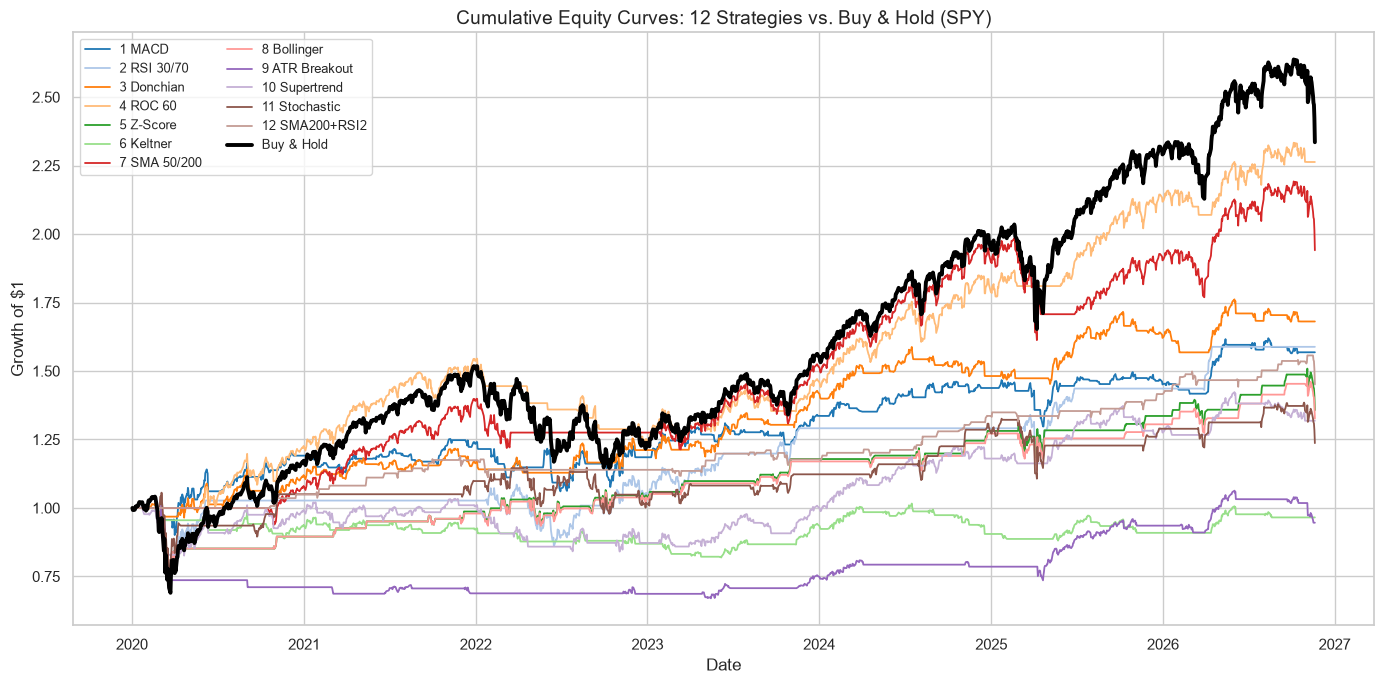

In [17]:
palette = sns.color_palette("tab20", n_colors=len(results))

fig, ax = plt.subplots(figsize=(14, 7))
for color, (name, res) in zip(palette, results.items()):
    ax.plot(res["bt"].index, res["bt"]["Equity"], label=name, color=color, linewidth=1.3)
ax.plot(bh_result["bt"].index, (1.0 + buy_hold_ret).cumprod(), label="Buy & Hold", color="black", linewidth=2.8)

ax.set_title("Cumulative Equity Curves: 12 Strategies vs. Buy & Hold (SPY)", fontsize=14)
ax.set_xlabel("Date")
ax.set_ylabel("Growth of $1")
ax.legend(loc="upper left", ncol=2, fontsize=9)
plt.tight_layout()
plt.show()

## 5.2 Underwater (Drawdown) Comparison
A drawdown is the percentage decline from the previous equity peak. The deeper and longer the "underwater" period, the harder the strategy is to hold in practice.

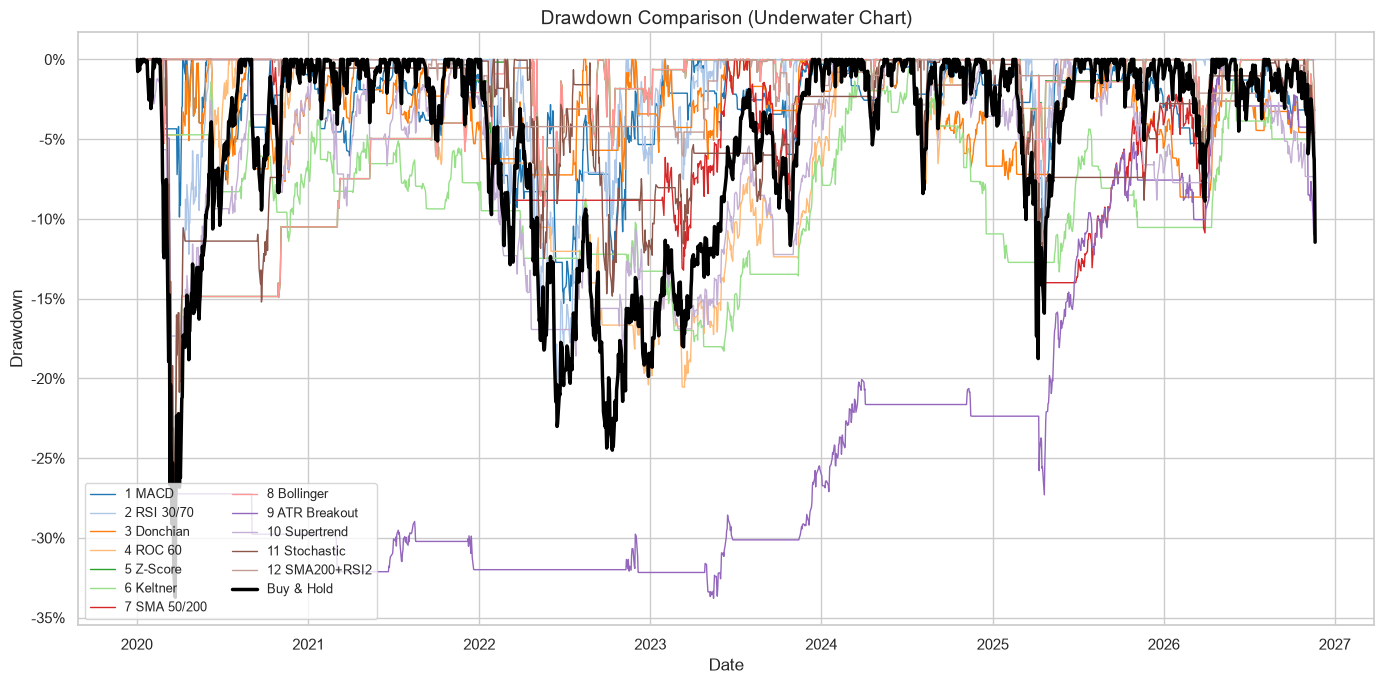

In [18]:
fig, ax = plt.subplots(figsize=(14, 7))
for color, (name, res) in zip(palette, results.items()):
    ax.plot(res["bt"].index, res["bt"]["Drawdown"], label=name, color=color, linewidth=1.0)

bh_drawdown = (1.0 + buy_hold_ret).cumprod()
bh_drawdown = bh_drawdown / bh_drawdown.cummax() - 1.0
ax.plot(bh_drawdown.index, bh_drawdown, label="Buy & Hold", color="black", linewidth=2.5)

ax.set_title("Drawdown Comparison (Underwater Chart)", fontsize=14)
ax.set_xlabel("Date")
ax.set_ylabel("Drawdown")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.legend(loc="lower left", ncol=2, fontsize=9)
plt.tight_layout()
plt.show()

## 5.3 Sharpe Ratio Ranking
The Sharpe ratio measures return per unit of risk. The dashed line marks the Buy & Hold Sharpe ratio, so bars to its right beat the benchmark on a risk-adjusted basis.

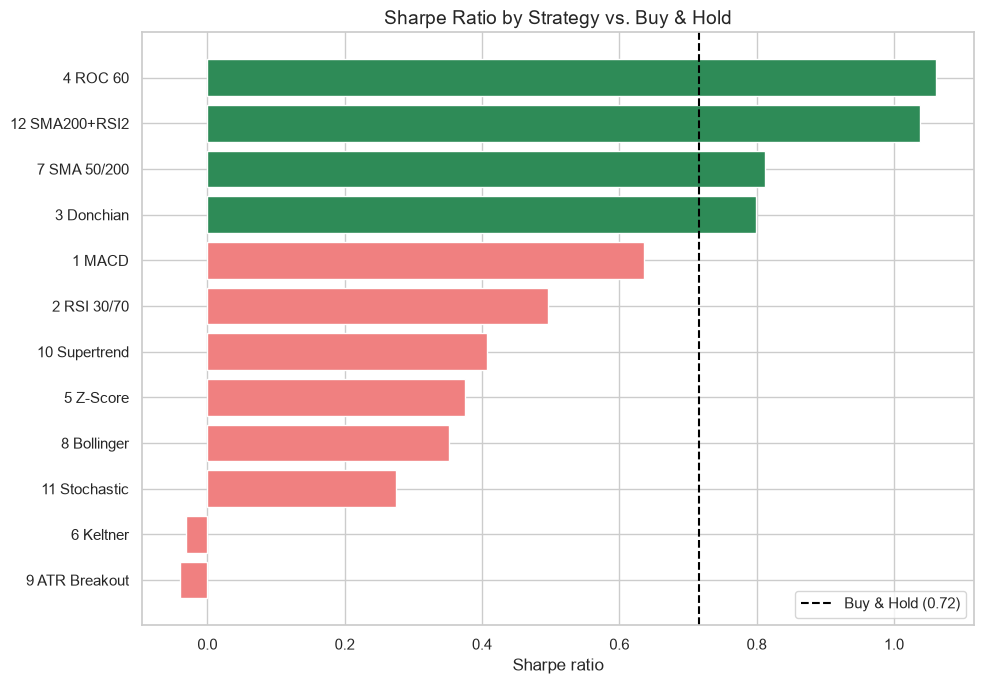

In [19]:
strategy_sharpe = comparison.drop("Buy & Hold")["Sharpe"].sort_values()
bar_colors = ["seagreen" if s > bh_metrics["Sharpe"] else "lightcoral" for s in strategy_sharpe]

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(strategy_sharpe.index, strategy_sharpe.values, color=bar_colors)
ax.axvline(bh_metrics["Sharpe"], color="black", linestyle="--", label=f"Buy & Hold ({bh_metrics['Sharpe']:.2f})")
ax.set_title("Sharpe Ratio by Strategy vs. Buy & Hold", fontsize=14)
ax.set_xlabel("Sharpe ratio")
ax.legend()
plt.tight_layout()
plt.show()

## 5.4 Risk-Return Map
Each point is one strategy: volatility on the x-axis and CAGR on the y-axis. Points toward the upper left deliver more return for less risk.

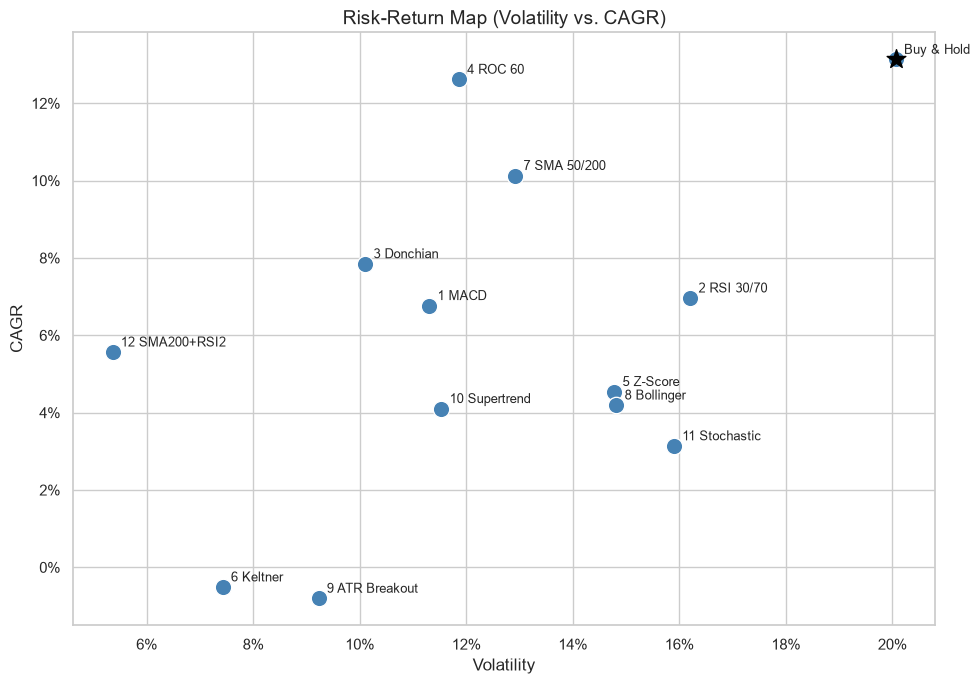

In [20]:
fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(data=comparison, x="Volatility", y="CAGR", s=140, color="steelblue", ax=ax)
for name, row in comparison.iterrows():
    ax.annotate(name, (row["Volatility"], row["CAGR"]), xytext=(6, 4), textcoords="offset points", fontsize=9)

ax.scatter(bh_metrics["Volatility"], bh_metrics["CAGR"], color="black", s=200, marker="*", zorder=5)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Risk-Return Map (Volatility vs. CAGR)", fontsize=14)
plt.tight_layout()
plt.show()

## 5.5 Distribution of Strategy Returns
Histograms and boxplots show how the daily returns of each strategy are distributed. Many strategies are flat on most days, so we only look at days when the strategy actually held a position.

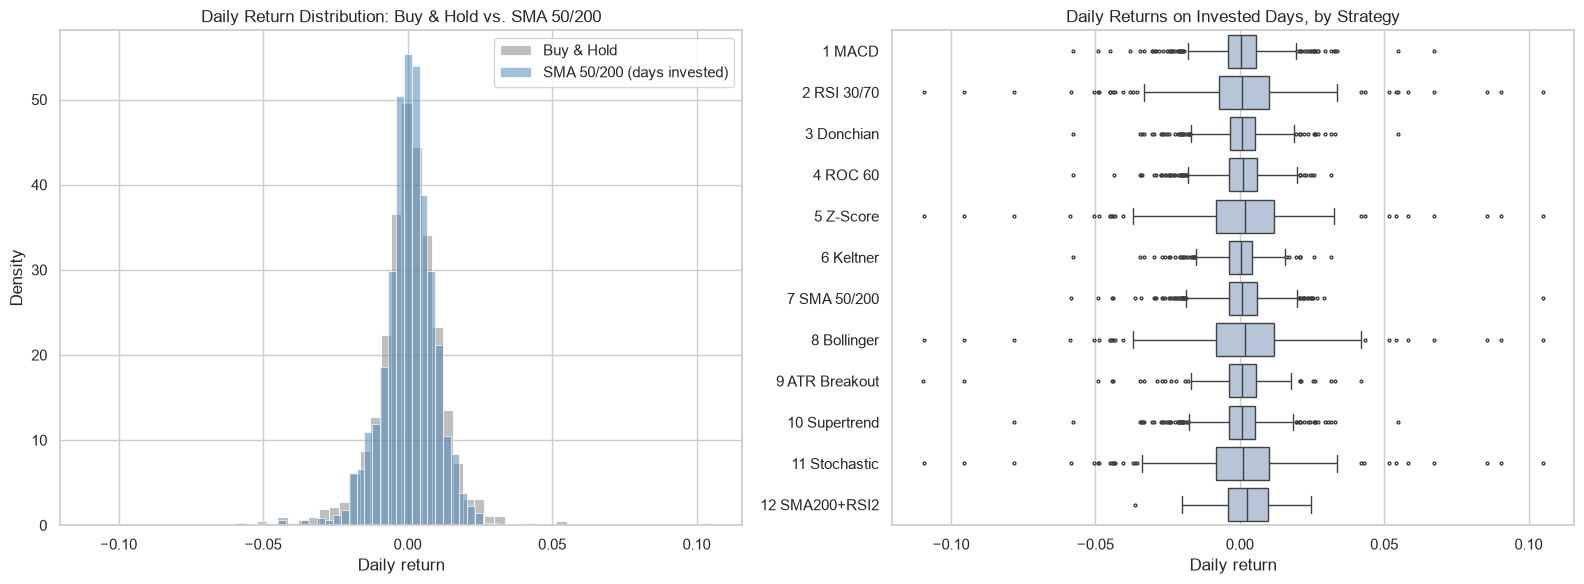

In [21]:
# Collect daily returns of each strategy, keeping only the days with an open position
active_returns = pd.DataFrame({
    name: res["bt"].loc[res["bt"]["Position"] == 1.0, "StrategyRet"] for name, res in results.items()
})

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.histplot(returns, bins=60, color="gray", label="Buy & Hold", stat="density", alpha=0.5, ax=axes[0])
sns.histplot(active_returns["7 SMA 50/200"].dropna(), bins=60, color="steelblue",
             label="SMA 50/200 (days invested)", stat="density", alpha=0.5, ax=axes[0])
axes[0].set_title("Daily Return Distribution: Buy & Hold vs. SMA 50/200")
axes[0].set_xlabel("Daily return")
axes[0].legend()

sns.boxplot(data=active_returns, orient="h", color="lightsteelblue", fliersize=2, ax=axes[1])
axes[1].set_title("Daily Returns on Invested Days, by Strategy")
axes[1].set_xlabel("Daily return")

plt.tight_layout()
plt.show()

## 5.6 Correlation of Strategy Returns
A correlation heatmap shows which strategies behave alike. Combining strategies with low correlation is what makes diversification across rules worthwhile.

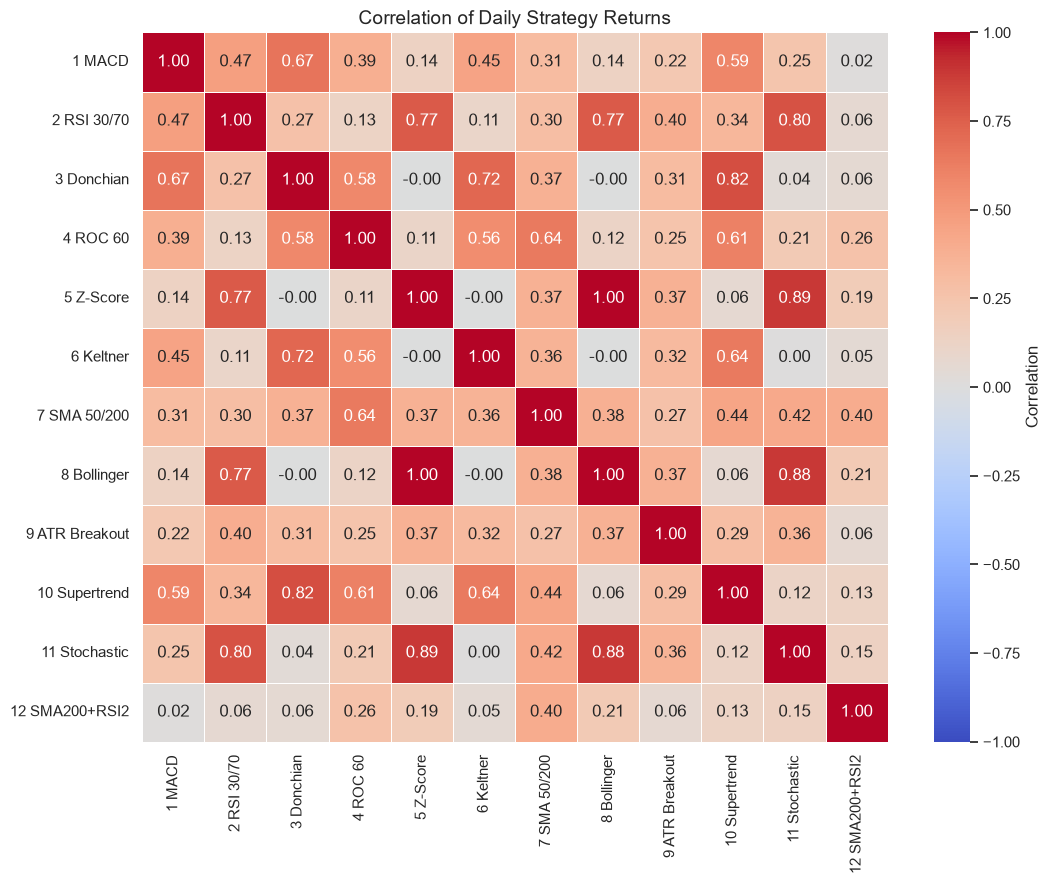

In [22]:
strategy_returns = pd.DataFrame({name: res["bt"]["StrategyRet"] for name, res in results.items()})
corr = strategy_returns.corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"label": "Correlation"})
plt.title("Correlation of Daily Strategy Returns", fontsize=14)
plt.tight_layout()
plt.show()

# 6. Single-Strategy Deep Dive and Conclusion
We now zoom in on the strategy with the highest Sharpe ratio. The top panel shows the SPY price with entry (green triangle) and exit (red triangle) markers, and the bottom panel compares its equity curve with Buy & Hold.

In [23]:
best_name = comparison.drop("Buy & Hold")["Sharpe"].idxmax()
best = results[best_name]
best_bt, best_trades = best["bt"], best["trades"]
print(f"Top strategy by Sharpe ratio: {best_name}")
print(f"Number of trades: {len(best_trades)}")

Top strategy by Sharpe ratio: 4 ROC 60
Number of trades: 24


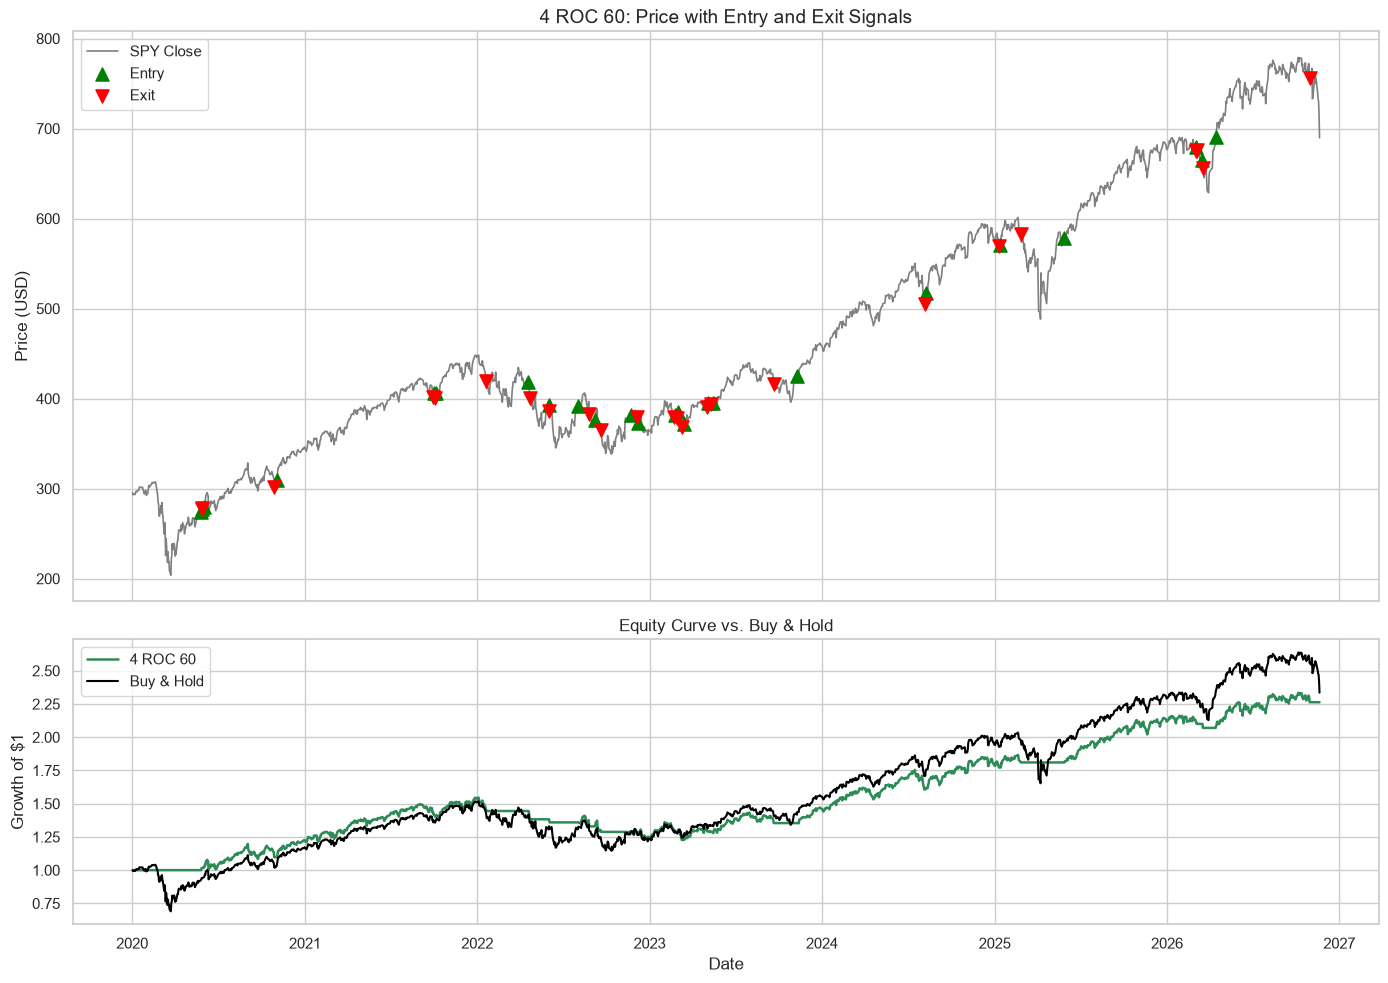

In [24]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True, gridspec_kw={"height_ratios": [2, 1]})

# Price with entry and exit markers (signal dates)
ax1.plot(df.index, df["Close"], color="gray", linewidth=1.2, label="SPY Close")
ax1.scatter(best_trades["Entry Date"], df.loc[best_trades["Entry Date"], "Close"],
            marker="^", color="green", s=90, label="Entry", zorder=5)
closed = best_trades[best_trades["Status"] == "Closed"]
ax1.scatter(closed["Exit Date"], df.loc[closed["Exit Date"], "Close"],
            marker="v", color="red", s=90, label="Exit", zorder=5)
ax1.set_title(f"{best_name}: Price with Entry and Exit Signals", fontsize=14)
ax1.set_ylabel("Price (USD)")
ax1.legend()

# Equity curve versus Buy & Hold
ax2.plot(best_bt.index, best_bt["Equity"], color="seagreen", linewidth=1.8, label=best_name)
ax2.plot(best_bt.index, (1.0 + buy_hold_ret).cumprod(), color="black", linewidth=1.5, label="Buy & Hold")
ax2.set_title("Equity Curve vs. Buy & Hold")
ax2.set_xlabel("Date")
ax2.set_ylabel("Growth of $1")
ax2.legend()

plt.tight_layout()
plt.show()

## 6.1 Trade Ledger
The table lists the first trades of the selected strategy. `Return` is the price return between entry and exit before transaction costs.

In [25]:
ledger = best_trades.copy()
ledger["Entry Date"] = ledger["Entry Date"].dt.date
ledger["Exit Date"] = ledger["Exit Date"].dt.date
ledger.head(10).style.format({"Entry Price": "{:.2f}", "Exit Price": "{:.2f}", "Return": "{:.2%}"})

,Entry Date,Exit Date,Entry Price,Exit Price,Return,Days Held,Status
0,2020-05-26,2020-05-27,273.54,277.61,1.49%,1,Closed
1,2020-05-28,2020-05-29,277.10,278.33,0.45%,1,Closed
2,2020-06-01,2020-10-28,279.46,301.28,7.81%,105,Closed
3,2020-11-03,2021-09-30,309.92,401.38,29.51%,228,Closed
4,2021-10-01,2021-10-04,406.15,400.91,-1.29%,1,Closed
5,2021-10-06,2022-01-20,406.76,419.31,3.09%,73,Closed
6,2022-04-19,2022-04-22,419.01,401.12,-4.27%,3,Closed
7,2022-06-02,2022-06-03,392.97,386.53,-1.64%,1,Closed
8,2022-08-03,2022-08-26,391.89,383.25,-2.21%,17,Closed
9,2022-09-07,2022-09-20,376.13,364.68,-3.04%,9,Closed


In [26]:
print(f"Winning trades: {(best_trades['Return'] > 0).sum()} of {len(best_trades)}")
print(f"Average trade return: {best_trades['Return'].mean():.2%}")
print(f"Average holding period: {best_trades['Days Held'].mean():.0f} trading days")
print(f"Best trade: {best_trades['Return'].max():.2%}   Worst trade: {best_trades['Return'].min():.2%}")

Winning trades: 13 of 24
Average trade return: 3.79%
Average holding period: 54 trading days
Best trade: 29.51%   Worst trade: -4.52%


## 6.2 Key Findings

In [27]:
top3 = comparison.drop("Buy & Hold").head(3)
print(f"Buy & Hold: CAGR {bh_metrics['CAGR']:.1%}, Sharpe {bh_metrics['Sharpe']:.2f}, Max Drawdown {bh_metrics['Max Drawdown']:.1%}")
print()
print("Top three strategies by Sharpe ratio:")
for name, row in top3.iterrows():
    print(f"  {name}: CAGR {row['CAGR']:.1%}, Sharpe {row['Sharpe']:.2f}, "
          f"Max Drawdown {row['Max Drawdown']:.1%}, Trades {int(row['# Trades'])}")
print()
beat_return = (comparison.drop("Buy & Hold")["CAGR"] > bh_metrics["CAGR"]).sum()
beat_dd = (comparison.drop("Buy & Hold")["Max Drawdown"] > bh_metrics["Max Drawdown"]).sum()
print(f"Strategies with a higher CAGR than Buy & Hold:          {beat_return} of {len(results)}")
print(f"Strategies with a shallower max drawdown than Buy & Hold: {beat_dd} of {len(results)}")

Buy & Hold: CAGR 13.1%, Sharpe 0.72, Max Drawdown -33.7%

Top three strategies by Sharpe ratio:
  4 ROC 60: CAGR 12.6%, Sharpe 1.06, Max Drawdown -20.5%, Trades 24
  12 SMA200+RSI2: CAGR 5.6%, Sharpe 1.04, Max Drawdown -6.8%, Trades 60
  7 SMA 50/200: CAGR 10.1%, Sharpe 0.81, Max Drawdown -18.8%, Trades 3

Strategies with a higher CAGR than Buy & Hold:          0 of 12
Strategies with a shallower max drawdown than Buy & Hold: 11 of 12


## Conclusion and Limitations
**What we did.** We downloaded daily SPY data, explored its return distribution and volatility, implemented 12 technical strategies with `pandas_ta`, and evaluated them with a causal vectorized backtest that trades on the next day and charges fees and spreads. The comparison table and charts above summarize their return, risk, and drawdown profiles against Buy & Hold.

**How to read the results.** The summary output above shows that most rules reduce drawdowns because they spend part of the time in cash, but doing so usually costs return in a strongly rising market. Trend-following rules tend to protect capital in sharp sell-offs, while mean-reversion rules trade often and are more sensitive to costs and to the chosen thresholds. The correlation heatmap shows that rules from the same family move together, so combining different families gives more diversification than combining similar ones.

**Limitations.**
- **Single asset and short sample:** results cover one ETF over almost seven years, including one extreme event (the 2020 crash), so they may not generalize.
- **In-sample parameters:** indicator settings are textbook defaults and were not tuned, but choosing the "best" strategy afterwards still involves selection bias.
- **Simplified costs:** fees and spreads are fixed; real execution involves slippage, taxes, and market impact.
- **Long/flat only:** the strategies never short and never use leverage.
- **No out-of-sample test:** a walk-forward or train/test split would be the natural next step.